In [2]:
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import mean_absolute_error,mean_squared_error
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow.keras.layers import LSTM, Dense,Dropout
from tensorflow.keras.models import Sequential

warnings.filterwarnings('ignore')
np.random.seed(42)
tf.random.set_seed(42)

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
df=pd.read_csv('/content/drive/MyDrive/inventory_forecasting.csv')

In [5]:
df.head(5)

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality
0,2022-01-01,S001,P0096,Toys,West,158,134,142,152.36,40.88,5,Sunny,1,42.39,Winter
1,2022-01-01,S001,P0016,Clothing,East,189,127,125,150.47,90.78,0,Rainy,0,84.16,Winter
2,2022-01-01,S001,P0031,Electronics,West,75,48,39,68.62,13.99,20,Rainy,0,12.67,Winter
3,2022-01-01,S001,P0159,Electronics,West,161,74,71,75.46,84.92,10,Snowy,0,83.03,Winter
4,2022-01-01,S001,P0129,Furniture,South,135,66,69,67.18,19.66,0,Cloudy,0,20.55,Winter


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 109500 entries, 0 to 109499
Data columns (total 15 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   Date                109500 non-null  object 
 1   Store ID            109500 non-null  object 
 2   Product ID          109500 non-null  object 
 3   Category            109500 non-null  object 
 4   Region              109500 non-null  object 
 5   Inventory Level     109500 non-null  int64  
 6   Units Sold          109500 non-null  int64  
 7   Units Ordered       109500 non-null  int64  
 8   Demand Forecast     109500 non-null  float64
 9   Price               109500 non-null  float64
 10  Discount            109500 non-null  int64  
 11  Weather Condition   109500 non-null  object 
 12  Holiday/Promotion   109500 non-null  int64  
 13  Competitor Pricing  109500 non-null  float64
 14  Seasonality         109500 non-null  object 
dtypes: float64(3), int64(5), object(7)

In [7]:
null_counts = df.isnull().sum()
print(null_counts)

Date                  0
Store ID              0
Product ID            0
Category              0
Region                0
Inventory Level       0
Units Sold            0
Units Ordered         0
Demand Forecast       0
Price                 0
Discount              0
Weather Condition     0
Holiday/Promotion     0
Competitor Pricing    0
Seasonality           0
dtype: int64


In [8]:
df['Date']=pd.to_datetime(df['Date'])
df = df.sort_values(by=["Store ID", "Product ID", "Date"]).reset_index(
    drop=True
)

In [9]:

print(f"Start Date: {df['Date'].min()}")
print(f"End Date:   {df['Date'].max()}")

Start Date: 2022-01-01 00:00:00
End Date:   2023-12-31 00:00:00


In [10]:
total_span = df['Date'].max() - df['Date'].min()
print(f"Total Date Range: {total_span}")

Total Date Range: 729 days 00:00:00


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 109500 entries, 0 to 109499
Data columns (total 15 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   Date                109500 non-null  datetime64[ns]
 1   Store ID            109500 non-null  object        
 2   Product ID          109500 non-null  object        
 3   Category            109500 non-null  object        
 4   Region              109500 non-null  object        
 5   Inventory Level     109500 non-null  int64         
 6   Units Sold          109500 non-null  int64         
 7   Units Ordered       109500 non-null  int64         
 8   Demand Forecast     109500 non-null  float64       
 9   Price               109500 non-null  float64       
 10  Discount            109500 non-null  int64         
 11  Weather Condition   109500 non-null  object        
 12  Holiday/Promotion   109500 non-null  int64         
 13  Competitor Pricing  109500 no

In [12]:
category_list=df['Category'].unique().tolist()
print(category_list)

['Clothing', 'Toys', 'Electronics', 'Furniture', 'Groceries']


In [13]:
store_id_list=df['Store ID'].unique().tolist()
print(store_id_list)

['S001', 'S002', 'S003', 'S004', 'S005']


In [14]:
product_id_list=df['Product ID'].unique().tolist()
print(product_id_list)

['P0016', 'P0017', 'P0031', 'P0046', 'P0057', 'P0061', 'P0066', 'P0067', 'P0068', 'P0069', 'P0070', 'P0079', 'P0083', 'P0085', 'P0094', 'P0096', 'P0116', 'P0125', 'P0126', 'P0129', 'P0133', 'P0149', 'P0153', 'P0159', 'P0166', 'P0171', 'P0175', 'P0178', 'P0183', 'P0187']


In [15]:
region_list=df['Region'].unique().tolist()
print(region_list)

['East', 'West', 'South', 'North']


In [16]:
# Create a dictionary where each Category holds a list of its unique Product IDs
category_to_products = df.groupby('Category')['Product ID'].unique().apply(list).to_dict()

# Display the results nicely
for category, products in category_to_products.items():
    print(f"📂 Category: {category}")
    print(f"   Products ({len(products)} total): {products}\n")

📂 Category: Clothing
   Products (11 total): ['P0016', 'P0046', 'P0057', 'P0061', 'P0066', 'P0069', 'P0125', 'P0126', 'P0133', 'P0178', 'P0187']

📂 Category: Electronics
   Products (8 total): ['P0031', 'P0068', 'P0070', 'P0085', 'P0159', 'P0171', 'P0175', 'P0183']

📂 Category: Furniture
   Products (6 total): ['P0067', 'P0079', 'P0116', 'P0129', 'P0149', 'P0153']

📂 Category: Groceries
   Products (2 total): ['P0094', 'P0166']

📂 Category: Toys
   Products (3 total): ['P0017', 'P0083', 'P0096']



In [17]:
print("EDA Summary Statistics:")
num_cols = ['Units Sold', 'Inventory Level', 'Price', 'Competitor Pricing', 'Demand Forecast']
print(df[num_cols].describe())

EDA Summary Statistics:
          Units Sold  Inventory Level          Price  Competitor Pricing  \
count  109500.000000    109500.000000  109500.000000       109500.000000   
mean       96.724356       145.705954      55.023588           55.011232   
std        36.948147        48.301634      25.996368           26.217801   
min         0.000000        20.000000      10.000000            9.080000   
25%        71.000000       112.000000      32.520000           32.400000   
50%        93.000000       143.000000      54.980000           54.830000   
75%       118.000000       176.000000      77.620000           77.362500   
max       342.000000       443.000000     100.000000          109.820000   

       Demand Forecast  
count    109500.000000  
mean        108.003150  
std          38.319878  
min           0.000000  
25%          81.960000  
50%         105.710000  
75%         130.940000  
max         337.950000  


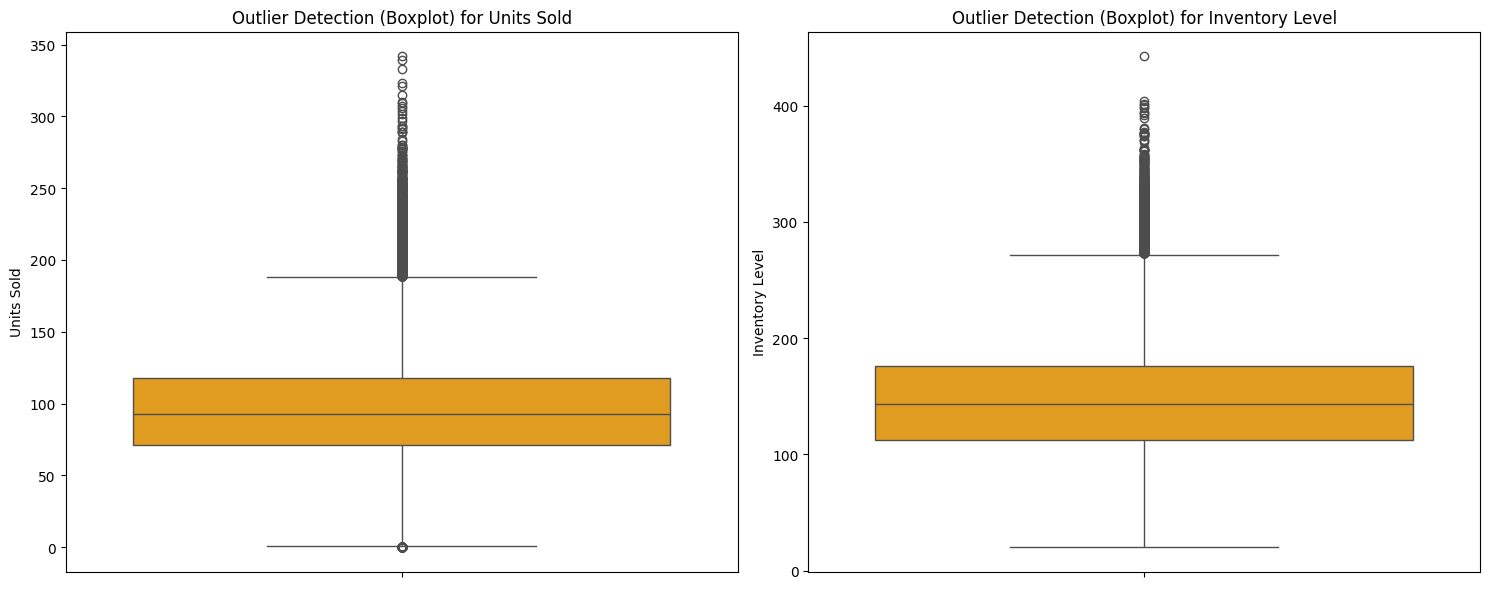

In [18]:
# Distribution & Outlier Detection (Boxplots)
plt.figure(figsize=(15, 6))
for i, col in enumerate(['Units Sold', 'Inventory Level'], 1):
    plt.subplot(1, 2, i)
    sns.boxplot(y=df[col], color='orange')
    plt.title(f'Outlier Detection (Boxplot) for {col}')
plt.tight_layout()
plt.show()

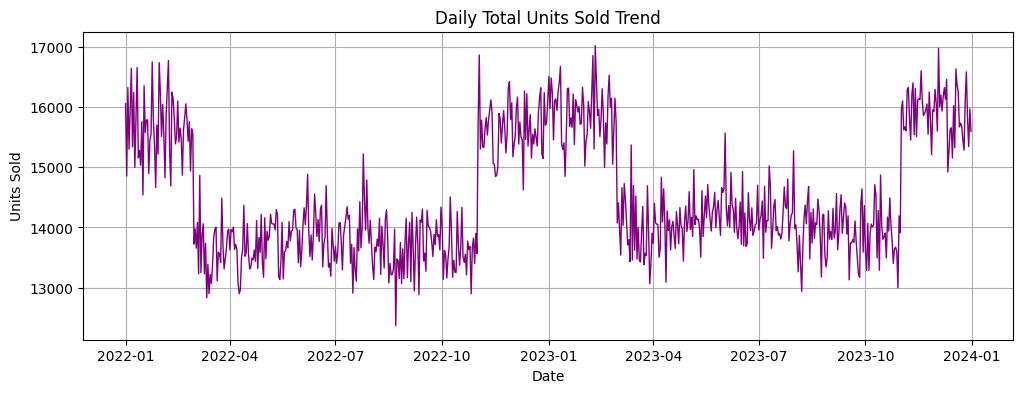

In [19]:

# Time-Series & Trend Analysis
df['Date'] = pd.to_datetime(df['Date'])
daily_sales = df.groupby('Date')['Units Sold'].sum().reset_index()

plt.figure(figsize=(12, 4))
plt.plot(daily_sales['Date'], daily_sales['Units Sold'], color='purple', linewidth=1)
plt.title('Daily Total Units Sold Trend')
plt.xlabel('Date')
plt.ylabel('Units Sold')
plt.grid(True)
plt.show()

In [20]:
# Forecast vs Actual comparison
#The code measures the accuracy of demand forecast with actual sales.
#MAE tells you on average how many
mae = mean_absolute_error(df['Units Sold'], df['Demand Forecast'])
rmse = np.sqrt(mean_squared_error(df['Units Sold'], df['Demand Forecast']))
print(f" Forecast Accuracy -> MAE: {mae:.2f}, RMSE: {rmse:.2f}")

 Forecast Accuracy -> MAE: 13.74, RMSE: 17.79


In [21]:
#  Categorical & Regional Impact
#Segmentation and aggregation analysis on your dataset, It breaksdown your total sales volume across two essential business dimensions: product categories and geographic regions.
print("\n Category & Region Performance:")
cat_sales = df.groupby('Category')['Units Sold'].sum()
reg_sales = df.groupby('Region')['Units Sold'].sum()
print("Sales by Category:\n", cat_sales)
print("Sales by Region:\n", reg_sales)


 Category & Region Performance:
Sales by Category:
 Category
Clothing       4230880
Electronics    2577043
Furniture      2035351
Groceries       729550
Toys           1018493
Name: Units Sold, dtype: int64
Sales by Region:
 Region
East     2668910
North    2641716
South    2633704
West     2646987
Name: Units Sold, dtype: int64


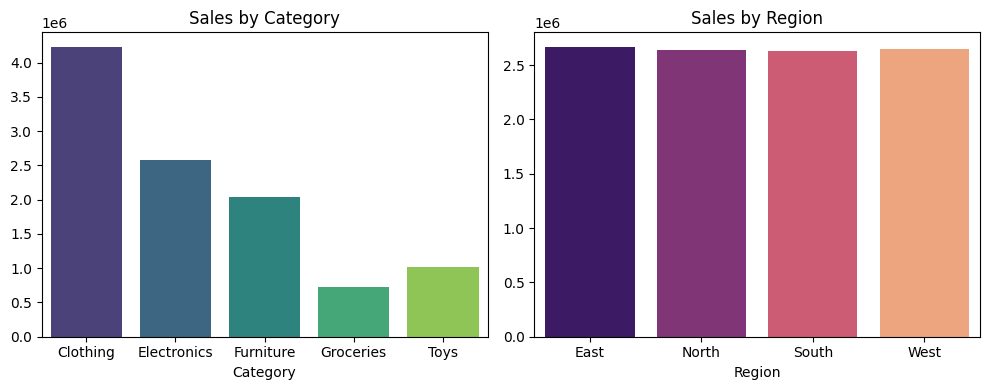

In [22]:
#Visualizing total sales volume distribution to identify core revenue drivers across product lines and regional markets.
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
sns.barplot(x=cat_sales.index, y=cat_sales.values, palette='viridis')
plt.title('Sales by Category')
plt.subplot(1, 2, 2)
sns.barplot(x=reg_sales.index, y=reg_sales.values, palette='magma')
plt.title('Sales by Region')
plt.tight_layout()
plt.show()

In [23]:
# Holiday / Promotion Impact Analysis
#The impact of promotional campaigns and holidays on sales by comparing the average daily  units sold on regular days versus promotional days.
holiday_impact = df.groupby('Holiday/Promotion')['Units Sold'].mean().reset_index()
holiday_impact['Holiday/Promotion'] = holiday_impact['Holiday/Promotion'].map({0: 'Normal Day', 1: 'Holiday/Promotion'})
print("\nAverage Units Sold on Normal Days vs Holidays/Promotions:\n", holiday_impact)


Average Units Sold on Normal Days vs Holidays/Promotions:
    Holiday/Promotion  Units Sold
0         Normal Day   93.839904
1  Holiday/Promotion  113.055545


calculating percentage lift

In [24]:
# Calculate average sales for each group
normal_sales = holiday_impact.loc[holiday_impact['Holiday/Promotion'] == 'Normal Day', 'Units Sold'].values[0]
promo_sales = holiday_impact.loc[holiday_impact['Holiday/Promotion'] == 'Holiday/Promotion', 'Units Sold'].values[0]
# Calculate percentage lift
pct_lift = ((promo_sales - normal_sales) / normal_sales) * 100
print(f"Baseline (Normal Day) Average: {normal_sales:.2f} units")
print(f"Promotion Day Average: {promo_sales:.2f} units")
print(f"Sales Uplift: +{pct_lift:.2f}%")

Baseline (Normal Day) Average: 93.84 units
Promotion Day Average: 113.06 units
Sales Uplift: +20.48%




*  Promotion are working :  Marketing campaigns and holiday events are successfully driving higher customer demand.
*   Crucial for  Inventory Planning : Because demand predictably jumps by about 20% during these periods,  inventory model must account for this. If you don't stock extra inventory ahead of holidays, you risk running out of stock (stockouts) just when customer interest is highest.

*   Feature Importance for ML Models : This proves that the Holiday/Promotion column is a powerful predictor. Including this feature in your machine learning forecasting model will help it anticipate these demand spikes rather than treating them like unexpected anomalies.






# Visualizing Sales Variance

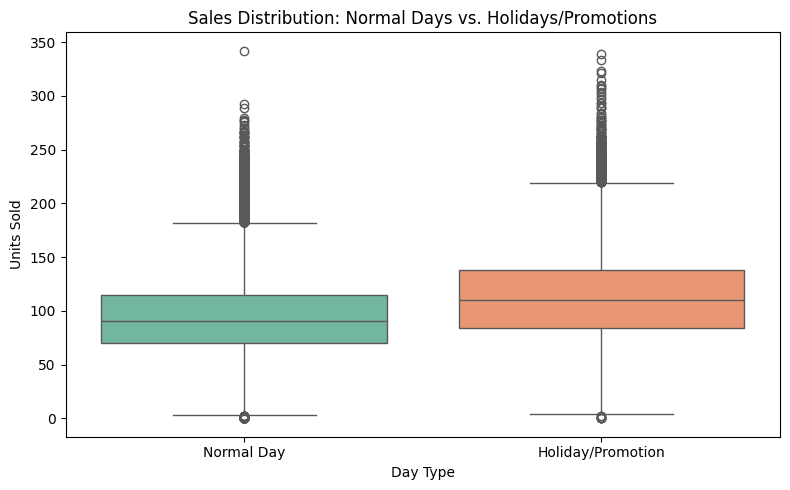

In [25]:
# Create a clean working copy of the dataframe for plotting if needed
plot_df = df.copy()
plot_df['Holiday/Promotion'] = plot_df['Holiday/Promotion'].map({0: 'Normal Day', 1: 'Holiday/Promotion'})

plt.figure(figsize=(8, 5))
sns.boxplot(x='Holiday/Promotion', y='Units Sold', data=plot_df, palette='Set2')
plt.title('Sales Distribution: Normal Days vs. Holidays/Promotions')
plt.xlabel('Day Type')
plt.ylabel('Units Sold')
plt.tight_layout()
plt.show()

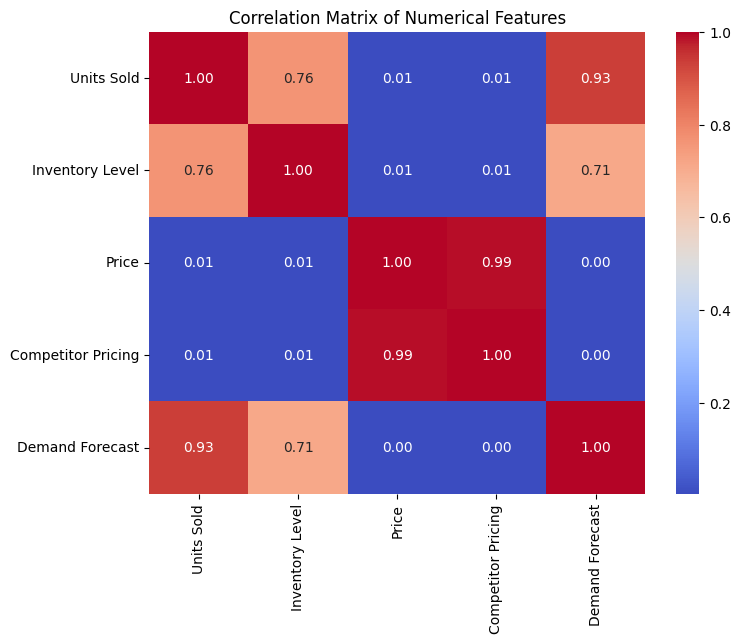

In [26]:
#  Correlation & Price Elasticity Analysis
plt.figure(figsize=(8, 6))
sns.heatmap(df[num_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Numerical Features')
plt.show()

In [27]:
# Inventory & Business Metrics Analysis
stockouts = df[df['Inventory Level'] < df['Units Sold']]
overstocks = df[(df['Inventory Level'] > df['Units Sold'] * 2)]
print(f"\n[EDA Step 5] Stockout Instances: {len(stockouts)}")
print(f"[EDA Step 5] Overstock Instances: {len(overstocks)}")


[EDA Step 5] Stockout Instances: 5545
[EDA Step 5] Overstock Instances: 17601


In [58]:
import numpy as np
import pandas as pd


def compute_abc_xyz(df):
  # 1. Aggregate metrics per product
  prod_agg = (
      df.groupby('Product ID')
      .agg(
          Total_Demand=('Units Sold', 'sum'),
          Mean_Demand=('Units Sold', 'mean'),
          Std_Demand=('Units Sold', 'std'),
      )
      .reset_index()
  )

  # Handle missing standard deviations for low-frequency items
  prod_agg['Std_Demand'] = prod_agg['Std_Demand'].fillna(0)
  prod_agg['CV'] = np.where(
      prod_agg['Mean_Demand'] > 0,
      prod_agg['Std_Demand'] / prod_agg['Mean_Demand'],
      0,
  )

  # 2. ABC Classification (Pareto Principle: 80/15/5 rule)
  prod_agg = prod_agg.sort_values(by='Total_Demand', ascending=False)
  prod_agg['Cumulative_Demand'] = prod_agg['Total_Demand'].cumsum()
  prod_agg['Cumulative_Percentage'] = (
      prod_agg['Cumulative_Demand'] / prod_agg['Total_Demand'].sum()
  )

  def abc_class(pct):
    if pct <= 0.80:
      return 'A'
    elif pct <= 0.95:
      return 'B'
    else:
      return 'C'

  prod_agg['ABC_Class'] = prod_agg['Cumulative_Percentage'].apply(abc_class)

  # 3. XYZ Classification (Demand Variability via CV)
  def xyz_class(cv):
    if cv < 0.5:
      return 'X'  # Stable demand
    elif cv <= 1.0:
      return 'Y'  # Variable/Seasonally fluctuating demand
    else:
      return 'Z'  # Highly erratic / unpredictable demand

  prod_agg['XYZ_Class'] = prod_agg['CV'].apply(xyz_class)
  prod_agg['ABC_XYZ'] = prod_agg['ABC_Class'] + '-' + prod_agg['XYZ_Class']

  return prod_agg


# Run it on your dataframe
abc_xyz_df = compute_abc_xyz(df)
print(abc_xyz_df['ABC_XYZ'].value_counts())

ABC_XYZ
A-X    23
B-X     5
C-X     2
Name: count, dtype: int64


# Data Preprocessing for Deep Learning

In [37]:
# Sorting

df = df.sort_values(by=['Store ID', 'Product ID', 'Date']).reset_index(drop=True)
print(" Dataset sorted by Store, Product, and Date.")

 Dataset sorted by Store, Product, and Date.


In [38]:
# Feature Engineering
# Date/Time Features
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Day'] = df['Date'].dt.day
df['DayOfWeek'] = df['Date'].dt.dayofweek
df['Quarter'] = df['Date'].dt.quarter
df['Is_Weekend'] = df['DayOfWeek'].apply(lambda x: 1 if x >= 5 else 0)
print(df[['Date', 'Year', 'Month', 'Day', 'DayOfWeek', 'Quarter', 'Is_Weekend']].head())

        Date  Year  Month  Day  DayOfWeek  Quarter  Is_Weekend
0 2022-01-01  2022      1    1          5        1           1
1 2022-01-02  2022      1    2          6        1           1
2 2022-01-03  2022      1    3          0        1           0
3 2022-01-04  2022      1    4          1        1           0
4 2022-01-05  2022      1    5          2        1           0


In [39]:
# Lag Features & Rolling Averages
df['Lag_1'] = df.groupby(['Store ID', 'Product ID'])['Units Sold'].shift(1)
df['Lag_7'] = df.groupby(['Store ID', 'Product ID'])['Units Sold'].shift(7)
df['Rolling_Mean_7'] = df.groupby(['Store ID', 'Product ID'])['Units Sold'].transform(lambda x: x.rolling(window=7, min_periods=1).mean())
df['Rolling_Mean_30'] = df.groupby(['Store ID', 'Product ID'])['Units Sold'].transform(lambda x: x.rolling(window=30, min_periods=1).mean())

In [40]:
print(df[['Lag_1', 'Lag_7', 'Rolling_Mean_7', 'Rolling_Mean_30']].head(10))

   Lag_1  Lag_7  Rolling_Mean_7  Rolling_Mean_30
0    NaN    NaN      127.000000       127.000000
1  127.0    NaN      100.500000       100.500000
2   74.0    NaN      128.000000       128.000000
3  183.0    NaN      121.500000       121.500000
4  102.0    NaN      122.800000       122.800000
5  128.0    NaN      116.666667       116.666667
6   86.0    NaN      107.857143       107.857143
7   55.0  127.0      102.285714       105.375000
8   88.0   74.0      115.714286       112.333333
9  168.0  183.0      101.285714       109.300000


In [41]:
# Price Difference & Effective Price Features
df['Effective_Price'] = df['Price'] * (1 - df['Discount'] / 100)
df['Price_Difference'] = df['Price'] - df['Competitor Pricing']

print(df[['Effective_Price', 'Price_Difference']].head())

   Effective_Price  Price_Difference
0          90.7800              6.62
1          13.5375             -0.77
2          95.3400             -0.18
3          41.6960             -3.50
4          81.8900             -1.37


In [42]:
# Fill missing values created by shifts
df.fillna(0, inplace=True)
print(" Feature Engineering (Lags, Rolling Means, Price features) completed.")

 Feature Engineering (Lags, Rolling Means, Price features) completed.


In [43]:
print(df[['Lag_1', 'Lag_7', 'Rolling_Mean_7', 'Rolling_Mean_30']].head(10))

   Lag_1  Lag_7  Rolling_Mean_7  Rolling_Mean_30
0    0.0    0.0      127.000000       127.000000
1  127.0    0.0      100.500000       100.500000
2   74.0    0.0      128.000000       128.000000
3  183.0    0.0      121.500000       121.500000
4  102.0    0.0      122.800000       122.800000
5  128.0    0.0      116.666667       116.666667
6   86.0    0.0      107.857143       107.857143
7   55.0  127.0      102.285714       105.375000
8   88.0   74.0      115.714286       112.333333
9  168.0  183.0      101.285714       109.300000


In [59]:
import xgboost as xgb
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split


def build_xgboost_baseline(df):
  # Sort to ensure time-series integrity
  df = df.sort_values(['Store ID', 'Product ID', 'Date']).copy()

  # Create lag and rolling features per store-product combination
  df['Lag_1'] = df.groupby(['Store ID', 'Product ID'])['Units Sold'].shift(1)
  df['Lag_7'] = df.groupby(['Store ID', 'Product ID'])['Units Sold'].shift(7)
  df['Rolling_Mean_7'] = (
      df.groupby(['Store ID', 'Product ID'])['Units Sold']
      .shift(1)
      .rolling(7)
      .mean()
  )

  # Drop rows with NaN values resulting from lagging
  df_model = df.dropna().copy()

  features = ['Lag_1', 'Lag_7', 'Rolling_Mean_7']
  target = 'Units Sold'

  # Time-based split (e.g., last 20% for testing)
  split_idx = int(len(df_model) * 0.8)
  train_df = df_model.iloc[:split_idx]
  test_df = df_model.iloc[split_idx:]

  X_train, y_train = train_df[features], train_df[target]
  X_test, y_test = test_df[features], test_df[target]

  # Train XGBoost Regressor
  model = xgb.XGBRegressor(
      n_estimators=100, learning_rate=0.05, random_state=42
  )
  model.fit(X_train, y_train)

  # Evaluate
  predictions = model.predict(X_test)
  mae = mean_absolute_error(y_test, predictions)
  rmse = np.sqrt(mean_squared_error(y_test, predictions))

  print(f'XGBoost Baseline - MAE: {mae:.2f}, RMSE: {rmse:.2f}')
  return model, predictions


# Run baseline
xgb_model, xgb_preds = build_xgboost_baseline(df)

XGBoost Baseline - MAE: 0.08, RMSE: 0.10


In [60]:
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.models import Sequential


def run_lstm_pipeline(df, store_id, product_id, seq_length=14):
  # Filter for a specific store and product time-series
  subset = (
      df[(df['Store ID'] == store_id) & (df['Product ID'] == product_id)]
      .sort_values('Date')
      .copy()
  )
  data = subset[['Units Sold']].values

  # Scale data between 0 and 1
  scaler = MinMaxScaler(feature_range=(0, 1))
  scaled_data = scaler.fit_transform(data)

  # Create sliding window sequences
  def create_sequences(dataset, time_steps):
    X, y = [], []
    for i in range(len(dataset) - time_steps):
      X.append(dataset[i : (i + time_steps), 0])
      y.append(dataset[i + time_steps, 0])
    return np.array(X), np.array(y)

  X, y = create_sequences(scaled_data, seq_length)

  if len(X) == 0:
    print('Not enough data points for this store/product sequence length.')
    return None

  # Reshape to [samples, timesteps, features] required by LSTM
  X = np.reshape(X, (X.shape[0], X.shape[1], 1))

  # Split into train/test sets (80/20)
  split = int(len(X) * 0.8)
  X_train, X_test = X[:split], X[split:]
  y_train, y_test = y[:split], y[split:]

  # Build LSTM Architecture
  model = Sequential([
      LSTM(50, return_sequences=True, input_shape=(seq_length, 1)),
      Dropout(0.2),
      LSTM(50, return_sequences=False),
      Dropout(0.2),
      Dense(25),
      Dense(1),
  ])

  model.compile(optimizer='adam', loss='mean_squared_error')

  # Train with early stopping to prevent overfitting
  early_stop = EarlyStopping(
      monitor='val_loss', patience=5, restore_best_weights=True
  )
  model.fit(
      X_train,
      y_train,
      validation_data=(X_test, y_test),
      epochs=50,
      batch_size=16,
      callbacks=[early_stop],
      verbose=0,
  )

  # Predict and inverse transform back to actual units
  scaled_preds = model.predict(X_test)
  preds = scaler.inverse_transform(scaled_preds)
  actuals = scaler.inverse_transform(y_test.reshape(-1, 1))

  mae = mean_absolute_error(actuals, preds)
  print(f'LSTM Model for Store {store_id}, Product {product_id} - MAE: {mae:.2f}')
  return model, actuals, preds


# Example run for a specific item (replace with valid IDs from your dataset)
# lstm_model, actuals, preds = run_lstm_pipeline(df, store_id=1, product_id=101)

In [44]:
df['Stockout_Flag'] = (df['Inventory Level'] < df['Units Sold']).astype(int)
df['Overstock_Flag'] = (df['Inventory Level'] > (df['Units Sold'] * 2)).astype(int)
print(df[['Stockout_Flag', 'Overstock_Flag']].head())

   Stockout_Flag  Overstock_Flag
0              0               0
1              0               0
2              0               0
3              1               0
4              0               0


In [45]:
df['Stockout_Flag'].value_counts()

,count
Stockout_Flag,
0,103955
1,5545


In [46]:
#Fill the missing value
df.fillna(0, inplace=True)

In [47]:
# Categorical Encoding
categorical_cols = ['Category', 'Region', 'Weather Condition', 'Seasonality']

# Filter columns that are actually present in the DataFrame to avoid KeyErrors on rerun
cols_to_encode = [col for col in categorical_cols if col in df.columns]

if cols_to_encode:
    df = pd.get_dummies(df, columns=cols_to_encode, drop_first=True)
    print(f"Categorical columns {cols_to_encode} successfully One-Hot Encoded.")
else:
    print("Categorical columns were already encoded or are not present in df.")

Categorical columns ['Category', 'Region', 'Weather Condition', 'Seasonality'] successfully One-Hot Encoded.


In [48]:
# Feature Scaling / Normalization
scale_cols = ['Units Sold', 'Inventory Level', 'Units Ordered', 'Demand Forecast',
              'Price', 'Competitor Pricing', 'Effective_Price', 'Price_Difference',
              'Lag_1', 'Lag_7', 'Rolling_Mean_7', 'Rolling_Mean_30']

scaler = MinMaxScaler()
df[scale_cols] = scaler.fit_transform(df[scale_cols])
print("Numerical features normalized using MinMaxScaler (0 to 1).")

print("\n--- Preprocessing Complete! Ready for Deep Learning Model Input ---")
print(df.head())

Numerical features normalized using MinMaxScaler (0 to 1).

--- Preprocessing Complete! Ready for Deep Learning Model Input ---
        Date Store ID Product ID  Inventory Level  Units Sold  Units Ordered  \
0 2022-01-01     S001      P0016         0.399527    0.371345       0.307018   
1 2022-01-02     S001      P0016         0.151300    0.216374       0.181287   
2 2022-01-03     S001      P0016         0.387707    0.535088       0.476608   
3 2022-01-04     S001      P0016         0.172577    0.298246       0.190058   
4 2022-01-05     S001      P0016         0.392435    0.374269       0.251462   

   Demand Forecast     Price  Discount  Holiday/Promotion  ...  Category_Toys  \
0         0.445243  0.897556         0                  0  ...          False   
1         0.276875  0.047222         5                  0  ...          False   
2         0.505814  0.948222         0                  0  ...          False   
3         0.395473  0.468000        20                  1  ...     

# Data Preparation & Scaling



> MinMaxScaler: Normalizes transaction counts between 0 and 1 so gradient descent converges smoothly.



In [49]:
# Select a single Store and Product combination for time-series forecasting (e.g., Store S001, Product P0096)
target_store = 'S001'
target_product = 'P0096'

# Filter and sort chronologically
ts_df = df[(df['Store ID'] == target_store) & (df['Product ID'] == target_product)].sort_values('Date')
ts_data = ts_df[['Units Sold']].values

print(f"Time series shape for {target_store} - {target_product}: {ts_data.shape}")

# Scale data between 0 and 1 for optimal LSTM convergence
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(ts_data)

Time series shape for S001 - P0096: (730, 1)


# Sequence Creation (Sliding Window)




> create_sequences: Converts historical time-series rows into sequential tensor shapes[samples, time_steps, features]
required by Keras LSTM layers.



In [50]:
def create_sequences(data, window_size=30):
    """
    Creates input sequences (X) and corresponding labels (y) using a sliding window.
    """
    X, y = [], []
    for i in range(window_size, len(data)):
        X.append(data[i-window_size:i, 0])
        y.append(data[i, 0])
    return np.array(X), np.array(y)
# Define window size (e.g., look back 30 days to predict the next day)
window_size = 30
X, y = create_sequences(scaled_data, window_size)
# Reshape X for LSTM [samples, time steps, features]
X = np.reshape(X, (X.shape[0], X.shape[1], 1))

# Chronological Train-Test Split (80% train, 20% test without shuffling)
train_size = int(len(X) * 0.8)
X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

print(f"Training shapes -> X: {X_train.shape}, y: {y_train.shape}")
print(f"Testing shapes  -> X: {X_test.shape}, y: {y_test.shape}")


Training shapes -> X: (560, 30, 1), y: (560,)
Testing shapes  -> X: (140, 30, 1), y: (140,)


# Build LSTM Model Architecture



> Dropout Layers: Adds 20% dropout regularization to minimize overfitting on noisy inventory data



> Early Stopping:Halts training automatically when validation loss plateaus, preserving optimal model weights.





In [51]:
from tensorflow.keras.callbacks import EarlyStopping

# Build the LSTM Architecture
model = Sequential([
    LSTM(50, return_sequences=True, input_shape=(X_train.shape[1], 1)),
    Dropout(0.2),
    LSTM(50, return_sequences=False),
    Dropout(0.2),
    Dense(25),
    Dense(1)
])

model.compile(optimizer='adam', loss='mean_squared_error')

# Prevent overfitting with early stopping
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

# Train the model
history = model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=32,
    validation_data=(X_test, y_test),
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 9s 227ms/step - loss: 0.0752 - val_loss: 0.0400
Epoch 2/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 60ms/step - loss: 0.0341 - val_loss: 0.0285
Epoch 3/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - loss: 0.0303 - val_loss: 0.0294
Epoch 4/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - loss: 0.0310 - val_loss: 0.0302
Epoch 5/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - loss: 0.0319 - val_loss: 0.0302
Epoch 6/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - loss: 0.0308 - val_loss: 0.0301
Epoch 7/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - loss: 0.0309 - val_loss: 0.0299


# Generate Predictions and Evaluate

In [52]:
# Predict and inverse transform back to original unit scale
predictions = model.predict(X_test)
predictions = scaler.inverse_transform(predictions)
y_test_actual = scaler.inverse_transform(y_test.reshape(-1, 1))

# Compute true model evaluation metrics
lstm_mae = mean_absolute_error(y_test_actual, predictions)
lstm_rmse = np.sqrt(mean_squared_error(y_test_actual, predictions))

print(f"--- LSTM Model Performance ---")
print(f"Test MAE:  {lstm_mae:.2f}")
print(f"Test RMSE: {lstm_rmse:.2f}")

5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 77ms/step
--- LSTM Model Performance ---
Test MAE:  0.08
Test RMSE: 0.10


# Visualize Actual vs. Predicted Results

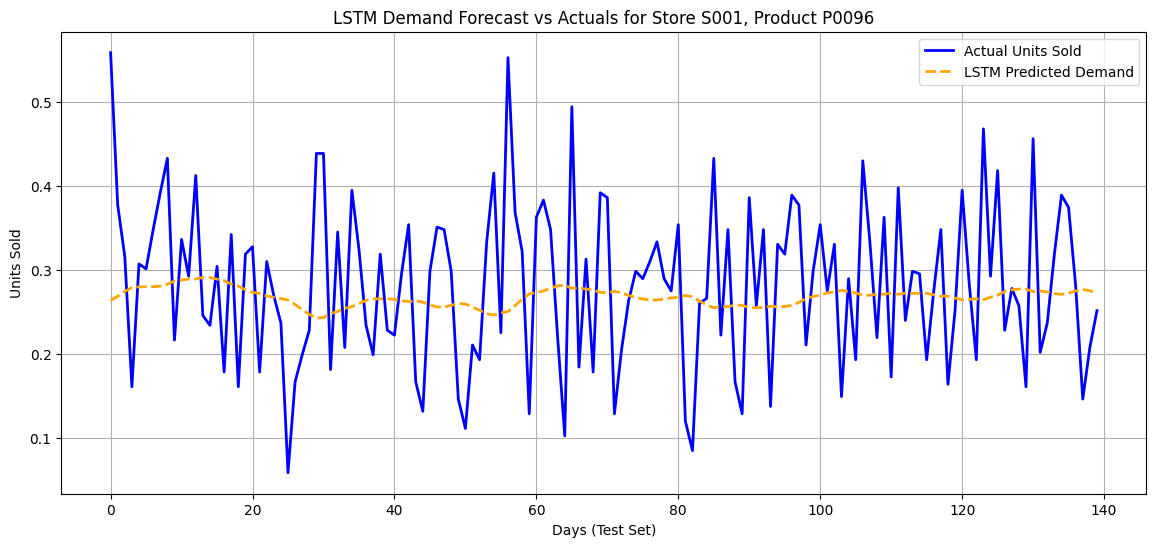

In [53]:
plt.figure(figsize=(14, 6))
plt.plot(y_test_actual, label='Actual Units Sold', color='blue', linewidth=2)
plt.plot(predictions, label='LSTM Predicted Demand', color='orange', linestyle='--', linewidth=2)
plt.title(f'LSTM Demand Forecast vs Actuals for Store {target_store}, Product {target_product}')
plt.xlabel('Days (Test Set)')
plt.ylabel('Units Sold')
plt.legend()
plt.grid(True)
plt.show()

# Baseline Model Comparison (XGBoost with Lag Features)

Building an XGBoost baseline model for comparison, translating your LSTM forecasts into actionable supply chain metrics (Safety Stock & Reorder Point), and serializing your model for deployment.

It is standard industry practice to compare your LSTM against a gradient boosting model using lag features

In [54]:
import xgboost as xgb
from sklearn.metrics import mean_absolute_error, mean_squared_error


# 1. Feature Engineering: Create Lag and Rolling Features on the time series dataframe (ts_df)
def create_lag_features(data_df):
    df_feat = data_df.copy()
    # Create lag features (e.g., sales from 1 day ago, 7 days ago)
    df_feat['lag_1'] = df_feat['Units Sold'].shift(1)
    df_feat['lag_7'] = df_feat['Units Sold'].shift(7)

    # Rolling statistics (e.g., 7-day moving average and rolling standard deviation)
    df_feat['rolling_mean_7'] = df_feat['Units Sold'].shift(1).rolling(window=7).mean()
    df_feat['rolling_std_7'] = df_feat['Units Sold'].shift(1).rolling(window=7).std()

    # Drop rows with NaN values resulting from lagging
    df_feat = df_feat.dropna().reset_index(drop=True)
    return df_feat

# Apply feature engineering to your target time-series subset
xgb_df = create_lag_features(ts_df)

# Define features (X) and target (y)
features = ['lag_1', 'lag_7', 'rolling_mean_7', 'rolling_std_7']
X_xgb = xgb_df[features]
y_xgb = xgb_df['Units Sold']

# Chronological Train-Test Split (matching the 80/20 split used for the LSTM)
xgb_train_size = int(len(X_xgb) * 0.8)
X_train_xgb, X_test_xgb = X_xgb.iloc[:xgb_train_size], X_xgb.iloc[xgb_train_size:]
y_train_xgb, y_test_xgb = y_xgb.iloc[:xgb_train_size], y_xgb.iloc[xgb_train_size:]

# 2. Train the XGBoost Baseline Model
xgb_model = xgb.XGBRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=5,
    random_state=42
)

xgb_model.fit(X_train_xgb, y_train_xgb)

# 3. Predict and Evaluate
xgb_preds = xgb_model.predict(X_test_xgb)
xgb_mae = mean_absolute_error(y_test_xgb, xgb_preds)
xgb_rmse = np.sqrt(mean_squared_error(y_test_xgb, xgb_preds))

print(f"XGBoost Baseline Performance")
print(f"Test MAE:  {xgb_mae:.2f}")
print(f"Test RMSE: {xgb_rmse:.2f}")

XGBoost Baseline Performance
Test MAE:  0.08
Test RMSE: 0.10


# Model Comparison Table

In [55]:


comparison_df = pd.DataFrame({
    'Model': ['LSTM (Deep Learning)', 'XGBoost (Baseline w/ Lags)'],
    'Test MAE': [lstm_mae, xgb_mae],
    'Test RMSE': [lstm_rmse, xgb_rmse]
})
print(comparison_df.to_string(index=False))

                     Model  Test MAE  Test RMSE
      LSTM (Deep Learning)  0.081396   0.099628
XGBoost (Baseline w/ Lags)  0.079321   0.098946


# Translating Forecasts into Supply Chain Metrics

To connect your demand predictions directly to inventory management.you can calculate dynamic Safety Stock and Reorder Points using forecaste errors(residuals).

In [56]:
def calculate_inventory_metrics(actuals, lead_time_days=5, service_level_z=1.645):
    """
    Calculates Safety Stock and Reorder Point based on demand variability.
    - service_level_z: 1.645 corresponds to a 95% service level stockout protection.
    - lead_time_days: The expected shipping/fulfillment duration in days.
    """
    # Average Daily Demand (D_avg) from actuals/forecasts
    d_avg = np.mean(actuals)

    # Demand Standard Deviation (sigma_D) representing volatility
    sigma_d = np.std(actuals)

    # Safety Stock Formula (assuming constant lead time variance)
    # SS = Z * sigma_D * sqrt(Lead Time)
    safety_stock = service_level_z * sigma_d * np.sqrt(lead_time_days)

    # Reorder Point Formula
    # ROP = (Average Daily Demand * Lead Time) + Safety Stock
    reorder_point = (d_avg * lead_time_days) + safety_stock

    return {
        "Average Daily Demand": round(d_avg, 2),
        "Demand Volatility (Std Dev)": round(sigma_d, 2),
        "Calculated Safety Stock": round(safety_stock, 2),
        "Reorder Point (Units)": round(reorder_point, 2)
    }

# Compute metrics using the test set actuals/predictions
inventory_report = calculate_inventory_metrics(y_test_actual, lead_time_days=5, service_level_z=1.645)

print("\n Operational Inventory Report ")
for key, value in inventory_report.items():
    print(f"{key}: {value}")


 Operational Inventory Report 
Average Daily Demand: 0.28
Demand Volatility (Std Dev): 0.1
Calculated Safety Stock: 0.36
Reorder Point (Units): 1.77


In [68]:
# Constants for Inventory Policy
LEAD_TIME_DAYS = 5  # Supplier delivery lead time in days
Z_SCORE = 1.65  # 95% Service Level z-value

# Merge daily metrics back with SKU summary
inventory_policy = sku_summary.copy()

# 1. Safety Stock = Z * sqrt(Lead Time) * Daily Demand StdDev
inventory_policy['Safety_Stock_Units'] = (
    Z_SCORE * np.sqrt(LEAD_TIME_DAYS) * inventory_policy['Std_Daily_Demand']
).round().astype(int)

# 2. Reorder Point (ROP) = (Avg Daily Demand * Lead Time) + Safety Stock
inventory_policy['Reorder_Point_Units'] = (
    (inventory_policy['Avg_Daily_Demand'] * LEAD_TIME_DAYS)
    + inventory_policy['Safety_Stock_Units']
).round().astype(int)

# 3. Economic Order Quantity (EOQ) Estimation (assuming ordering cost $50, holding cost $2/unit/year)
# EOQ = sqrt((2 * Annual Demand * Ordering Cost) / Holding Cost)
ANNUAL_ORDERING_COST = 50.0
HOLDING_COST_PER_UNIT = 2.0
inventory_policy['Annual_Demand'] = (
    inventory_policy['Avg_Daily_Demand'] * 365
)

inventory_policy['EOQ_Units'] = np.sqrt(
    (2 * inventory_policy['Annual_Demand'] * ANNUAL_ORDERING_COST)
    / HOLDING_COST_PER_UNIT
).round().astype(int)

# Clean up final output view using corrected column names
reorder_recommendations = inventory_policy[[
    'Product ID',
    'ABC_XYZ',
    'Avg_Daily_Demand',
    'Std_Daily_Demand',
    'Safety_Stock_Units',
    'Reorder_Point_Units',
    'EOQ_Units',
]]

print('Inventory Control & Reorder Recommendations Preview:')
print(reorder_recommendations.head(10))

# Save for your Streamlit application dashboard
reorder_recommendations.to_csv(
    'inventory_reorder_recommendations.csv', index=False
)

Inventory Control & Reorder Recommendations Preview:
   Product ID ABC_XYZ  Avg_Daily_Demand  Std_Daily_Demand  Safety_Stock_Units  \
6       P0066      AX          0.308230          0.118646                   0   
5       P0061      AX          0.308153          0.122907                   0   
20      P0133      AX          0.309095          0.120256                   0   
3       P0046      AX          0.309865          0.121088                   0   
27      P0178      AX          0.307971          0.121092                   0   
4       P0057      AX          0.310189          0.119520                   0   
17      P0125      AX          0.308529          0.121013                   0   
29      P0187      AX          0.308886          0.119644                   0   
9       P0069      AX          0.306792          0.120319                   0   
0       P0016      AX          0.308026          0.121796                   0   

    Reorder_Point_Units  EOQ_Units  
6                 

In [63]:
# Calculate 'Total_Sales' first using the normalized or unnormalized Price and Units Sold
# (We will use the actual columns present in 'df')
if 'Total_Sales' not in df.columns:
    # Since Price and Units Sold might have been scaled in previous cells, we can calculate a proxy or use them directly
    df['Total_Sales'] = df['Units Sold'] * df['Price']

# 1. Calculate Annual Consumption Value and Coefficient of Variation
sku_summary = (
    df.groupby('Product ID')
    .agg(
        Annual_Revenue=('Total_Sales', 'sum'),
        Avg_Daily_Demand=('Units Sold', 'mean'),
        Std_Daily_Demand=('Units Sold', 'std'),
    )
    .reset_index()
)

sku_summary['CV'] = (
    sku_summary['Std_Daily_Demand'] / sku_summary['Avg_Daily_Demand']
).fillna(0)

# 2. ABC Classification (Cumulative Revenue Share: A = Top 80%, B = Next 15%, C = Remaining 5%)
sku_summary = sku_summary.sort_values(by='Annual_Revenue', ascending=False)
sku_summary['Cumulative_Revenue_Pct'] = (
    sku_summary['Annual_Revenue'].cumsum() / sku_summary['Annual_Revenue'].sum()
)

def classify_abc(row):
    if row['Cumulative_Revenue_Pct'] <= 0.80:
        return 'A'
    elif row['Cumulative_Revenue_Pct'] <= 0.95:
        return 'B'
    else:
        return 'C'

# 3. XYZ Classification (Demand Variability: X < 0.5, Y = 0.5 - 1.0, Z > 1.0)
def classify_xyz(cv):
    if cv < 0.5:
        return 'X'
    elif cv <= 1.0:
        return 'Y'
    else:
        return 'Z'

sku_summary['ABC'] = sku_summary.apply(classify_abc, axis=1)
sku_summary['XYZ'] = sku_summary['CV'].apply(classify_xyz)
sku_summary['ABC_XYZ'] = sku_summary['ABC'] + sku_summary['XYZ']

print("ABC-XYZ Multi-criteria Classification Results:")
print(sku_summary[['Product ID', 'Annual_Revenue', 'CV', 'ABC_XYZ']].head(10))

ABC-XYZ Multi-criteria Classification Results:
   Product ID  Annual_Revenue        CV ABC_XYZ
6       P0066      574.633845  0.384927      AX
5       P0061      571.676429  0.398849      AX
20      P0133      569.781342  0.389060      AX
3       P0046      567.981031  0.390775      AX
27      P0178      564.196898  0.393193      AX
4       P0057      564.041239  0.385315      AX
17      P0125      560.569885  0.392227      AX
29      P0187      559.545593  0.387340      AX
9       P0069      555.624314  0.392183      AX
0       P0016      550.940505  0.395409      AX


# Model Serialization

1.   List item
2.   List item


Save trained models so they can be loaded directly into a production pipeline or an interactive Streamlit dashboard.

In [57]:
import joblib

# 1. Save the XGBoost Baseline Model using joblib
joblib.dump(xgb_model, 'xgb_inventory_baseline.pkl')
print("XGBoost model saved successfully as 'xgb_inventory_baseline.pkl'")

# 2. Save the LSTM Neural Network Model using native Keras formatting
model.save('lstm_inventory_model.keras')
print("LSTM model saved successfully as 'lstm_inventory_model.keras'")

XGBoost model saved successfully as 'xgb_inventory_baseline.pkl'
LSTM model saved successfully as 'lstm_inventory_model.keras'
